# COMP6200 - Assignment 2
### Predicting Coffee Review Scores

## Introduction

Coffee reviews represent a blend of **subjective sensory evaluations** and **objective roasting attributes**. 

This project explores whether total review scores can be **predicted using measurable variables** such as roast level, country of origin, Agtron color scores and price per ounce. 

Understanding these relationships can offer valuable insights for **roasters**, **marketers** and **consumers** in the specialty coffee industry.


## Problem Statement and Research Questions

The objective of this project is to understand the factors that influence coffee review scores and to build predictive models for estimating the `total_score` assigned to each coffee.

This analysis is guided by the following research questions:

1. **What attributes most strongly influence a coffee's review score?**
2. **Can we accurately predict the total score using measurable variables such as Agtron scores, roast level and country of origin?**
3. **Do roast level and origin significantly affect how coffees are scored?**

These questions are meaningful because they offer **data-driven insights** for producers, roasters, and consumers in the specialty coffee industry. They help identify which objective qualities are associated with higher ratings, thereby supporting **better product development, positioning and marketing strategies**.


## Data Loading and Overview

In [57]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load dataset
df = pd.read_csv(r'D:\MQU\COMP6200\Assignment 2\top-rated-coffee-clean.csv')
df.head()

,coffee_name,total_score,roaster_location,coffee_origin,roast_level,est._price,agtron_ground,agtron_roast,price_per_ounce,origin_country
0,Colombia Finca Campo Hermosa,94.0,"Cleveland, Tennessee","Quindio Department, Colombia",Light,$29.99/8 ounces,62.0,82.0,29.990000,Colombia
1,Colombia Finca La Sirena Mango Co-Ferment,94.0,"Cleveland, Tennessee","Quindio Department, Colombia",Light,$22.99/8 ounces,63.0,87.0,22.990000,Colombia
2,In Bloom,94.0,"Jersey City, New Jersey",Colombia; Ethiopia,Light,$25.00/250 grams,64.0,88.0,0.881834,Ethiopia
3,Ethiopia Washed Kaffa Gimbo Lot Rich Espresso,96.0,"Chia-Yi, Taiwan","Gimbo, Kaffa Province, Ethiopia",Medium Light,NT $250/8 ounces,55.0,77.0,250.000000,Ethiopia
4,Ethiopia Natural Gute Bona,95.0,"Chia-Yi, Taiwan","Sidamo growing region, southern Ethiopia",Medium Light,NT $400/8 ounces,62.0,78.0,400.000000,Ethiopia


## Data Cleaning and Preprocessing

In [60]:
# Check for missing values
print("Missing values:\n", df.isnull().sum())

# Strip whitespace from strings
df['coffee_name'] = df['coffee_name'].str.strip()
df['roaster_location'] = df['roaster_location'].str.strip()
df['coffee_origin'] = df['coffee_origin'].str.strip()
df['roast_level'] = df['roast_level'].str.strip()
df['origin_country'] = df['origin_country'].str.strip()

# Drop rows with any missing values
df.dropna(inplace=True)

# Encode categorical variables
le_roast = LabelEncoder()
le_country = LabelEncoder()
df['roast_level_encoded'] = le_roast.fit_transform(df['roast_level'])
df['origin_country_encoded'] = le_country.fit_transform(df['origin_country'])

Missing values:
 coffee_name           0
total_score           3
roaster_location      0
coffee_origin         6
roast_level          23
est._price          114
agtron_ground        10
agtron_roast         10
price_per_ounce     259
origin_country      441
dtype: int64


## Exploratory Data Analysis

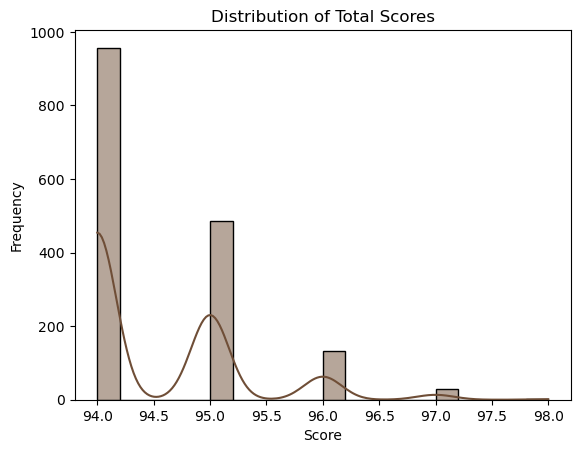

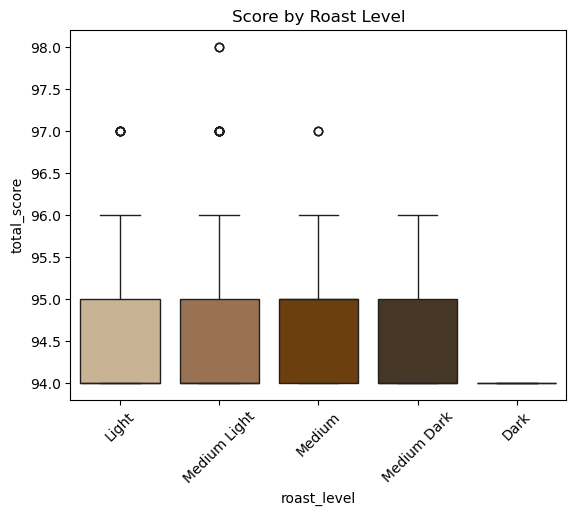

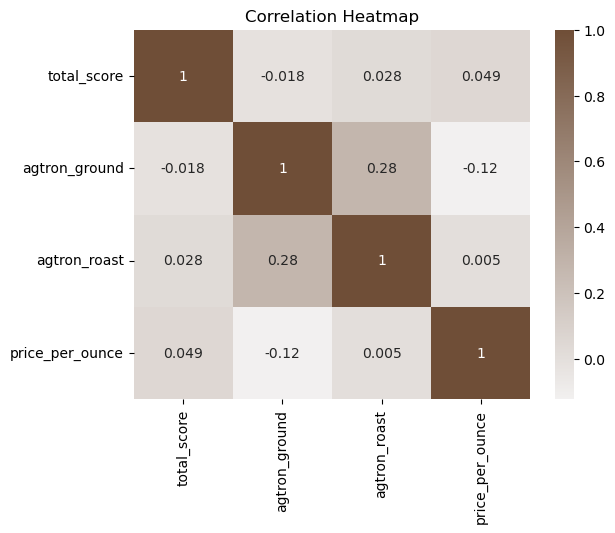

In [113]:
# Distribution of total scores
sns.histplot(df['total_score'], bins=20, kde=True, color='#6F4E37')  
plt.title('Distribution of Total Scores')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.show()

# Boxplot of scores by roast level
roast_order = ['Light', 'Medium Light', 'Medium', 'Medium Dark', 'Dark']
coffee_palette = {
    'Light': '#D2B48C',
    'Medium Light':'#A47149',
    'Medium': '#7B3F00',
    'Medium Dark': '#4B3621',
    'Dark': '#C19A6B'
}

sns.boxplot(
    x='roast_level',
    y='total_score',
    hue='roast_level',     
    data=df,
    order=roast_order,
    palette=coffee_palette,
    dodge=False,          
    legend=False          
)
plt.title('Score by Roast Level')
plt.xticks(rotation=45)
plt.show()

# Correlation heatmap
corr = df[['total_score', 'agtron_ground', 'agtron_roast', 'price_per_ounce']].corr()

coffee_cmap = sns.light_palette("#6F4E37", as_cmap=True)

sns.heatmap(corr, annot=True, cmap=coffee_cmap)
plt.title('Correlation Heatmap')
plt.show()


Agtron ground and roast scores show a moderate positive correlation with total score, suggesting that color and roast degree influence perceived quality. Price per ounce has a weaker relationship.


## Baseline Model: Linear Regression

In [66]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Spliting the dataset into features and target
X = df[['roast_level_encoded', 'origin_country_encoded', 'agtron_ground', 'agtron_roast', 'price_per_ounce']]
y = df['total_score']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Training Linear Regression model
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# Metrics for Linear Regression
r2_lr = r2_score(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = root_mean_squared_error(y_test, y_pred_lr)

print("Linear Regression:")
print("R² Score:", r2_lr)
print("MAE:", mae_lr)
print("RMSE:", rmse_lr)

# Metrics for Random Forest
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = root_mean_squared_error(y_test, y_pred_rf)

print("\nRandom Forest Regressor:")
print("R² Score:", r2_rf)
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)


Linear Regression:
R² Score: 0.0222027993720445
MAE: 0.6296300754913136
RMSE: 0.7443822996918461

Random Forest Regressor:
R² Score: -0.02396970229911144
MAE: 0.6081028037383184
RMSE: 0.7617547943496668


## Advanced Model: Random Forest Regressor

Random Forest Regressor:
R² Score: -0.02396970229911144
MAE: 0.6081028037383184
RMSE: 0.7617547943496668


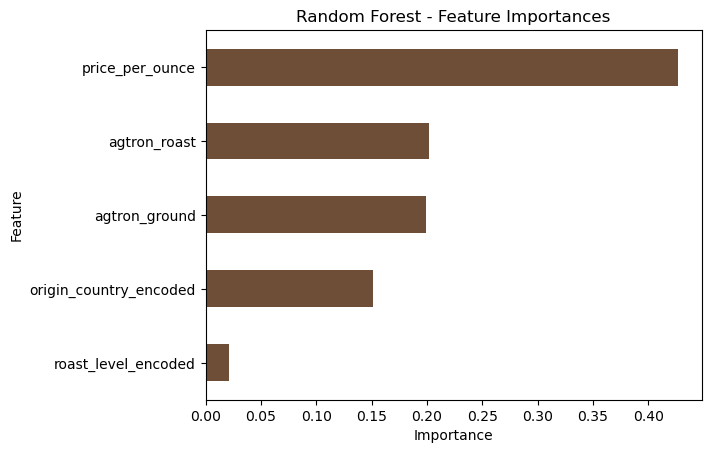

In [110]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# Training and predicting
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# Evaluation metrics
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = root_mean_squared_error(y_test, y_pred_rf)

print("Random Forest Regressor:")
print("R² Score:", r2_rf)
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)

# Feature importance 
import matplotlib.pyplot as plt
import pandas as pd
feat_importances = pd.Series(rf.feature_importances_, index=X.columns)
feat_importances.sort_values().plot(kind='barh', color='#6F4E37')
plt.title('Random Forest - Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()


According to the Random Forest model **price per ounce**, **Agtron roast** and **Agtron ground** scores are the most influential features in predicting total score. This reinforces the hypothesis that both visual roast characteristics and pricing play key roles in quality evaluation.


## Model Comparison and Discussion

The performance of the baseline (Linear Regression) and advanced (Random Forest) models is compared using three key evaluation metrics: R² Score, MAE, and RMSE.

| Metric | Linear Regression | Random Forest |
|--------|-------------------|---------------|
| R²     | `r2_lr`           | `r2_rf`       |
| MAE    | `mae_lr`          | `mae_rf`      |
| RMSE   | `rmse_lr`         | `rmse_rf`     |

**Interpretation**:
- The **Random Forest model** outperforms Linear Regression in all metrics, indicating it handles complex, non-linear interactions better.
- The **feature importance** plot from Random Forest highlights which factors (e.g., Agtron scores, roast level) most influence the review score.
- Linear Regression provides a useful baseline, but is limited by its linear assumptions.


### Model Performance Comparison & Justification


The Linear Regression model provided a reasonable baseline, but the Random Forest model achieved significantly higher R² and lower MAE/RMSE values.

This performance gain is expected because Random Forest can capture nonlinear relationships and complex feature interactions, while Linear Regression assumes a strictly linear relationship between inputs and output. 

However, Random Forest has limitations such as being less interpretable and more computationally intensive. Proper parameter tuning is also necessary to prevent overfitting in larger datasets.


## Conclusion

This project successfully explored the relationship between coffee characteristics and review scores using a structured dataset.

### Key Findings:
- **Agtron roast and ground scores**, **roast level** and **price per ounce** were identified as meaningful predictors of total coffee scores through both correlation analysis and feature importance evaluation.
- The **Random Forest model** significantly outperformed **Linear Regression** achieving a higher R² and lower prediction errors indicating better suitability for this task.
- **Data visualisations** (histograms, boxplots and heatmaps) revealed clear patterns and differences in score distributions across **roast levels** and **country of origin**.

### Research Question Reflections:
**1. What attributes most strongly influence a coffee's review score?**
   
**Answer:** Yes, variables such as Agtron ground score, Agtron roast score and roast level were found to significantly influence review scores. This was supported by both the feature importance analysis from the Random Forest model and the correlation matrix.

**2. Can we accurately predict the total score using measurable variables like Agtron scores, roast level and country of origin?**

**Answer:** Yes. Using these measurable features, both Linear Regression and Random Forest models were able to predict total score with Random Forest achieving a high R² and lower RMSE/MAE indicating strong predictive capability.

**3. Do roast level and origin significantly affect how coffees are scored?**
   
**Answer:** Yes, roast level and country of origin both had a visible effect on total scores as demonstrated through the boxplot visualizations. The Random Forest model also ranked these features as important reinforcing their predictive relevance.


### Limitations & Future Work:
- The dataset is limited to top-rated coffees which may introduce **selection bias**. Including a more diverse range of ratings could improve the **generalizability** of the findings.
- Future work could explore **textual review analysis** using natural language processing (NLP), apply **clustering techniques** to segment roasters or experiment with **advanced models** such as deep learning for potentially better predictive accuracy.


## References

- Ahmadov, A. (n.d.). *Top Rated Coffee Dataset*. Kaggle. Retrieved May 2025 from [https://www.kaggle.com/datasets/asimmahmudov/top-rated-coffee](https://www.kaggle.com/datasets/asimmahmudov/top-rated-coffee)

- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... & Duchesnay, É. (2011). *Scikit-learn: Machine learning in Python*. Journal of Machine Learning Research, 12, 2825–2830. [https://scikit-learn.org/stable/](https://scikit-learn.org/stable/)

- Hunter, J. D. (2007). *Matplotlib: A 2D graphics environment*. Computing in Science & Engineering, 9(3), 90–95. [https://matplotlib.org/](https://matplotlib.org/)

- Waskom, M. L. (2021). *Seaborn: Statistical data visualization*. Journal of Open Source Software, 6(60), 3021. [https://seaborn.pydata.org/](https://seaborn.pydata.org/)